# Illustrative pilot economics

Quantify Case Competition 2026 · Team Analysts

This notebook runs without organizer data. Every economic parameter below is an illustrative assumption, not a TSI fact or final quote. The purpose is to identify conditions that change the entry decision.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
while not (ROOT / "src" / "analysis.py").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Run this notebook inside the repository")
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")


In [2]:
from src.pilot import Pilot, covered_indemnity, common_vendor_stress
from dataclasses import replace

base = Pilot(policies=100, premium_per_policy=5_000,
             variable_expense_ratio=.25, fixed_cost=100_000,
             claim_frequency=.02, mean_covered_cost=100_000,
             target_margin=.10)
display(pd.Series(base.__dict__, name="Illustrative assumption"))
result = base.result()
print(f"Break-even frequency: {result['break_even_frequency']:.2%}")
print(f"Frequency for 10% underwriting margin: {result['target_margin_frequency']:.2%}")

policies                     100.0000
premium_per_policy         5,000.0000
variable_expense_ratio         0.2500
fixed_cost               100,000.0000
claim_frequency                0.0200
mean_covered_cost        100,000.0000
target_margin                  0.1000
Name: Illustrative assumption, dtype: float64

Break-even frequency: 2.75%
Frequency for 10% underwriting margin: 2.25%


## Annual frequency scenarios

Assume 100 full policy-years, not 100 partial-year launches. Covered cost includes defence in this example. Reinsurance, taxes, investment returns and capital charges are not separately modeled.

In [3]:
rows = [replace(base, claim_frequency=f).result() for f in [.01,.02,.03]]
display(pd.DataFrame(rows)[["claim_frequency", "earned_premium_cad", "expected_covered_cost_cad", "underwriting_profit_cad", "combined_ratio"]])
assert abs(replace(base, claim_frequency=.0275).result()["underwriting_profit_cad"]) < 1e-6

,claim_frequency,earned_premium_cad,expected_covered_cost_cad,underwriting_profit_cad,combined_ratio
0,0.0100,500000,"100,000.0000","175,000.0000",0.6500
1,0.0200,500000,"200,000.0000","75,000.0000",0.8500
2,0.0300,500000,"300,000.0000","-25,000.0000",1.0500


## Premium and covered severity sensitivity

The required source of each parameter differs: willingness to pay from customers, frequency from exposure-based evidence, covered severity from contract mapping, and expenses from the implementation budget.

annual_premium_cad,3000,5000,7000
mean_covered_cost_cad,,,
50000,0.0250,0.0550,0.0850
100000,0.0125,0.0275,0.0425
200000,0.0063,0.0138,0.0213


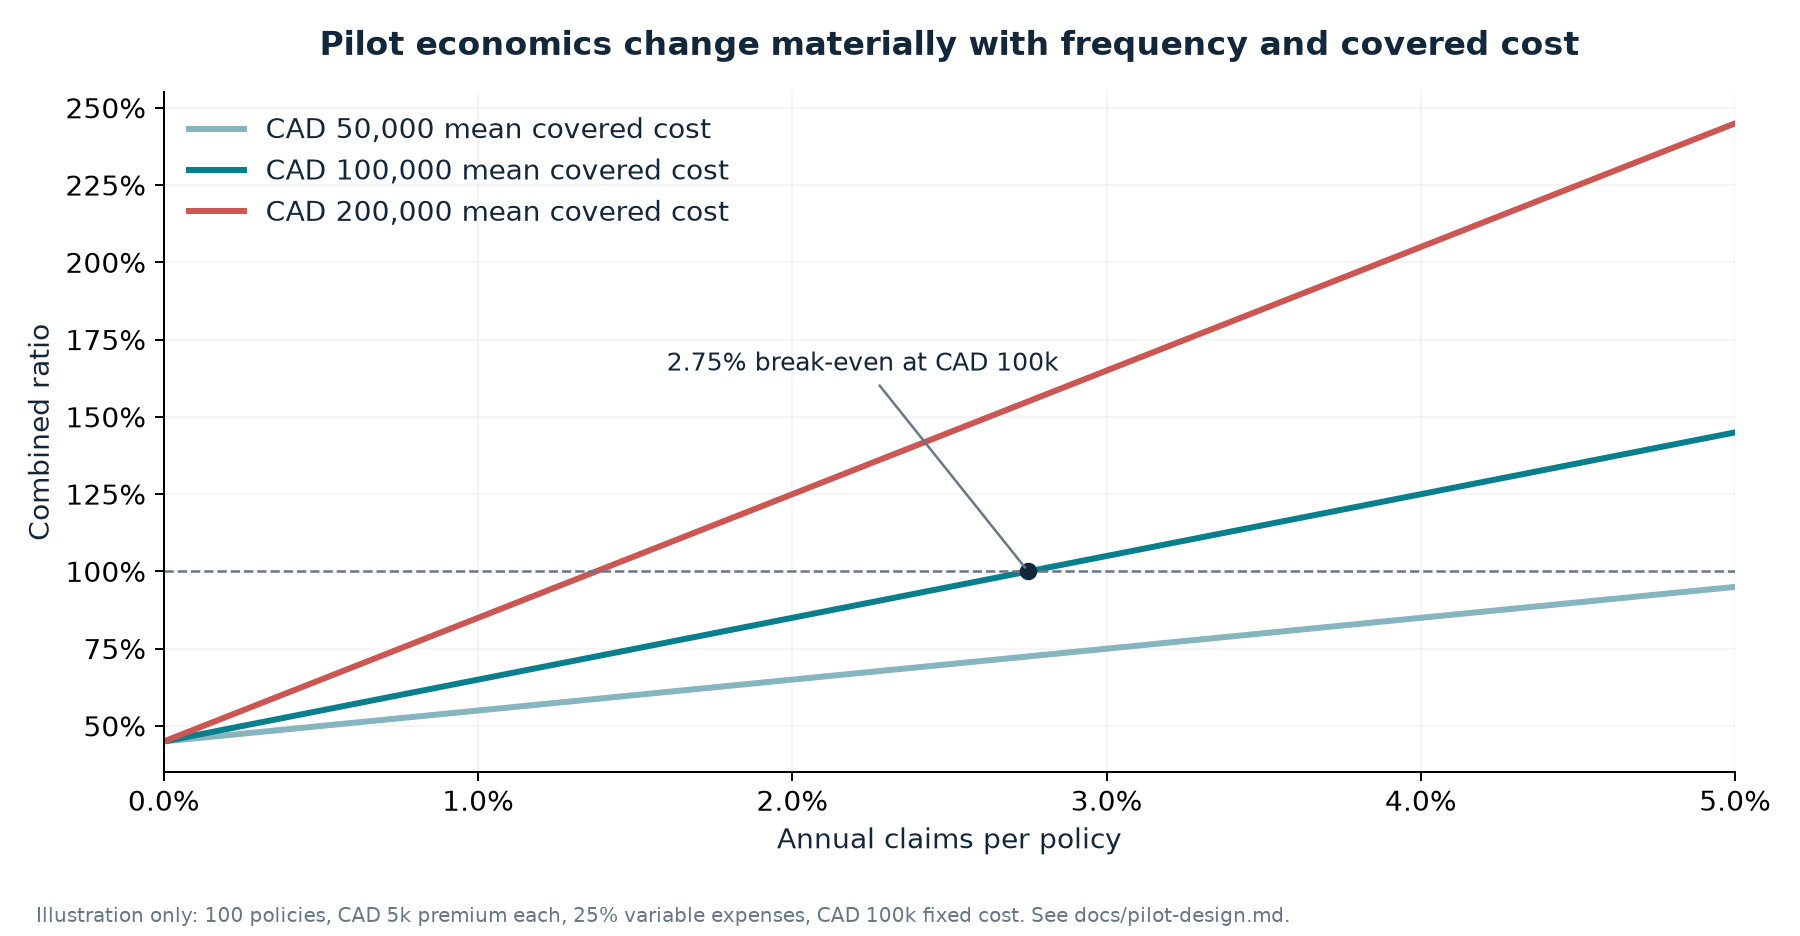

In [4]:
sensitivity = []
for premium in [3_000,5_000,7_000]:
    for cost in [50_000,100_000,200_000]:
        r = replace(base, premium_per_policy=premium, mean_covered_cost=cost).result()
        sensitivity.append({"annual_premium_cad":premium,"mean_covered_cost_cad":cost,
                            "break_even_frequency":r["break_even_frequency"]})
display(pd.DataFrame(sensitivity).pivot(index="mean_covered_cost_cad", columns="annual_premium_cad", values="break_even_frequency"))
display(Image(filename=str(ROOT / "figures/pilot-sensitivity.png")))

## Loss estimates are not policy payouts

The simplified indemnity formula below applies a deductible and a single-claim limit. It intentionally excludes defence, aggregate exhaustion and reinsurance. Those need explicit contract treatment before calibration.

In [5]:
display(pd.DataFrame([{"ground_up_loss_cad":loss,
                       "indemnity_cad":covered_indemnity(loss,10_000,250_000)}
                      for loss in [5_000,10_000,100_000,300_000,1_000_000]]))

,ground_up_loss_cad,indemnity_cad
0,5000,0.0000
1,10000,0.0000
2,100000,"90,000.0000"
3,300000,"250,000.0000"
4,1000000,"250,000.0000"


## Common-vendor stress

Twenty affected policies at CAD 250,000 each give a CAD 5M gross scenario. The CAD 2M budget below is an assumption used only to demonstrate the decision rule; it is not a recommended or observed TSI capacity.

In [6]:
display(pd.DataFrame([common_vendor_stress(n,250_000,2_000_000) | {"affected_policies":n}
                      for n in [5,10,20]]))

,gross_stress_cad,risk_budget_cad,within_budget,affected_policies
0,1250000,2000000,True,5
1,2500000,2000000,False,10
2,5000000,2000000,False,20


## Decision rule

Launch only if customer willingness to pay supports technical price, scope adds clear value, model/vendor stress fits approved capacity and operating gates are ready. Restrict future writing when an approved threshold is breached. A first renewal can assess continuation, but mature liability development is needed before broad expansion. Existing obligations survive an exit from new business.